In [11]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing()

print(data.data.shape)
print(data.target.shape)

(20640, 8)
(20640,)


In [12]:
X = pd.DataFrame(data.data, columns=data.feature_names)
print(X.head())
y = data.target
print(y)

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
[4.526 3.585 3.521 ... 0.923 0.847 0.894]


In [13]:
# Now lets find the missing values
X_df = pd.DataFrame(data.data, columns=data.feature_names)
y_series = pd.Series(data.target, name="MedHouseVal")

print(X_df.isnull().sum())

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


In [14]:
# check the duplicate data
print("Duplicate rows:", X_df.duplicated().sum())
print(y_series.describe())

Duplicate rows: 0
count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64


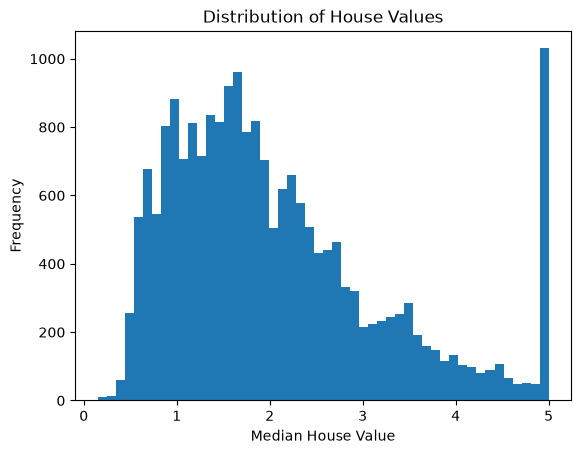

In [15]:
#As mean > median -> suspect ki right skewness h, lets draw histogram
import matplotlib.pyplot as plt
plt.hist(y_series, bins=50)
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.title("Distribution of House Values")
plt.show()

In [16]:
# lets split the data
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

X_train, X_test, y_train, y_test = train_test_split(
    X_df,
    y_series,
    random_state=42,
    test_size=0.2
)

model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [17]:
model.get_params()

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

In [18]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training predictions:", y_train_pred[:5])
print("Actual values:", y_train.iloc[:5].values)

print("Test predictions:", y_test_pred[:5])
print("Actual values:", y_test.iloc[:5].values)

Training predictions: [1.03  3.821 1.726 0.934 0.965]
Actual values: [1.03  3.821 1.726 0.934 0.965]
Test predictions: [0.414   1.203   5.00001 2.17    2.257  ]
Actual values: [0.477   0.458   5.00001 2.186   2.78   ]


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))

Train MAE: 4.217126217568424e-17
Test MAE: 0.4541711942829458
Train RMSE: 3.0176010694886063e-16
Test RMSE: 0.7030332265476953
Train R2: 1.0
Test R2: 0.622823312540521


As we can see that model is overfitting so we train 3 trees using max_depth = 3, 5, 10 to compare and get better results.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

X_train, X_test, y_train, y_test = train_test_split(
    X_df,
    y_series,
    random_state=42,
    test_size=0.2
)

model = DecisionTreeRegressor(
    random_state=42,
    max_depth=3
)

model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [23]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training predictions:", y_train_pred[:5])
print("Actual:", y_train.iloc[:5].values)

print("Test prediction:", y_test_pred[:5])
print("Actual:", y_test.iloc[:5].values)

Training predictions: [1.86688424 2.73565309 1.86688424 1.62582288 2.73565309]
Actual: [1.03  3.821 1.726 0.934 0.965]
Test prediction: [1.62582288 1.16511993 2.73565309 2.63556245 1.86688424]
Actual: [0.477   0.458   5.00001 2.186   2.78   ]


In [24]:
from sklearn.metrics import root_mean_squared_error
#for max_depth = 3
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train MSE:", mean_squared_error(y_train, y_train_pred))
print("Test MSE:", mean_squared_error(y_test, y_test_pred))

print("Train RMSE:", root_mean_squared_error(y_train, y_train_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_test_pred))

Train MAE: 0.5887239198385058
Test MAE: 0.5978280732432435
Train MSE: 0.61772790023286
Test MSE: 0.6424109810265641
Train RMSE: 0.7859566783435713
Test RMSE: 0.8015054466605727


In [25]:
# do for depth = 5
model = DecisionTreeRegressor(
    random_state=42,
    max_depth=5
)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [26]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training predictions:", y_train_pred[:5])
print("Actual:", y_train.iloc[:5].values)

print("Test prediction:", y_test_pred[:5])
print("Actual:", y_test.iloc[:5].values)

Training predictions: [1.64279735 3.19958174 2.33790011 1.16857267 3.19958174]
Actual: [1.03  3.821 1.726 0.934 0.965]
Test prediction: [1.16857267 1.27158128 3.19958174 2.20476301 1.64279735]
Actual: [0.477   0.458   5.00001 2.186   2.78   ]


In [27]:
#for max_depth = 5
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train MSE:", mean_squared_error(y_train, y_train_pred))
print("Test MSE:", mean_squared_error(y_test, y_test_pred))

print("Train RMSE:", root_mean_squared_error(y_train, y_train_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_test_pred))

Train MAE: 0.5063471123358746
Test MAE: 0.5222592972077786
Train MSE: 0.48434327650090625
Test MSE: 0.5245146178314735
Train RMSE: 0.6959477541460323
Test RMSE: 0.7242338143386247


In [28]:
# do for depth = 10
model = DecisionTreeRegressor(
    random_state=42,
    max_depth=10
)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [29]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training predictions:", y_train_pred[:5])
print("Actual:", y_train.iloc[:5].values)

print("Test prediction:", y_test_pred[:5])
print("Actual:", y_test.iloc[:5].values)

Training predictions: [1.4508125  4.20029173 2.02044055 0.90834524 2.30386   ]
Actual: [1.03  3.821 1.726 0.934 0.965]
Test prediction: [0.55230097 0.72655118 4.96858    2.25404687 2.04551471]
Actual: [0.477   0.458   5.00001 2.186   2.78   ]


In [30]:
#for max_depth = 10
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train MSE:", mean_squared_error(y_train, y_train_pred))
print("Test MSE:", mean_squared_error(y_test, y_test_pred))

print("Train RMSE:", root_mean_squared_error(y_train, y_train_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_test_pred))

Train MAE: 0.3191957491376588
Test MAE: 0.4334879123691683
Train MSE: 0.2208657912045762
Test MSE: 0.41648854728960316
Train RMSE: 0.46996360625539524
Test RMSE: 0.645359238943399


In [31]:
# for 20 depth
model = DecisionTreeRegressor(
    random_state=42,
    max_depth=20
)

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Train MAE: 0.02304703689142057
Test MAE: 0.4503853107006001
Train RMSE: 0.07567759221698284
Test RMSE: 0.6999587900497017


In [32]:
# now we do the cross validation
from sklearn.model_selection import cross_val_score

for depth in [3,5,10,20]:
    model = DecisionTreeRegressor(
        random_state=42,
        max_depth=depth
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    print(
        f"Depth {depth}: "
        f"Fold MAEs = {-scores.round(3)}, "
        f"Mean CV MAE = {-scores.mean():.4f}"
    )

Depth 3: Fold MAEs = [0.61  0.581 0.594 0.607 0.609], Mean CV MAE = 0.6002
Depth 5: Fold MAEs = [0.538 0.511 0.507 0.527 0.515], Mean CV MAE = 0.5193
Depth 10: Fold MAEs = [0.433 0.428 0.408 0.424 0.423], Mean CV MAE = 0.4232
Depth 20: Fold MAEs = [0.474 0.463 0.454 0.464 0.451], Mean CV MAE = 0.4612


In [33]:
#Now lets test first
final_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

final_model.fit(X_train, y_train)

y_test_prediction = final_model.predict(X_test)
print("Test MAE:", mean_absolute_error(y_test, y_test_prediction))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_prediction)))
print("Test R2:", r2_score(y_test, y_test_prediction))

Test MAE: 0.4334879123691683
Test RMSE: 0.645359238943399
Test R2: 0.6821690371438849


In [34]:
# check for min_leaf = 10
for leaf in [1,5,10,20]:
    model = DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=leaf,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    print(f"min_samples_leaf={leaf}: CV MAE={-scores.mean():.4f}")

min_samples_leaf=1: CV MAE=0.4232
min_samples_leaf=5: CV MAE=0.4154
min_samples_leaf=10: CV MAE=0.4161
min_samples_leaf=20: CV MAE=0.4163


In [38]:
# for min sample = 10
for split in [2, 5, 10, 20, 30, 40]:
    model = DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=5,
        min_samples_split=split,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    print(
        f"min_samples_split={split}: "
        f"CV MAE={-scores.mean():.4f}"
    )

min_samples_split=2: CV MAE=0.4154
min_samples_split=5: CV MAE=0.4154
min_samples_split=10: CV MAE=0.4154
min_samples_split=20: CV MAE=0.4149
min_samples_split=30: CV MAE=0.4149
min_samples_split=40: CV MAE=0.4136


In [39]:
# ccp_alpha
for alpha in [0.0, 0.001, 0.005, 0.01, 0.02]:
    model = DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=5,
        min_samples_split=40,
        ccp_alpha=alpha,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    print(f"ccp_alpha={alpha}: CV MAE={-scores.mean():.4f}")

ccp_alpha=0.0: CV MAE=0.4136
ccp_alpha=0.001: CV MAE=0.4458
ccp_alpha=0.005: CV MAE=0.5197
ccp_alpha=0.01: CV MAE=0.5681
ccp_alpha=0.02: CV MAE=0.6101


In [40]:
final_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    min_samples_split=40,
    ccp_alpha=0.0,
    random_state=42
)

final_model.fit(X_train, y_train)
y_test_pred = final_model.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))
print("Test R2:", r2_score(y_test, y_test_pred))

Test MAE: 0.42379155985511396
Test RMSE: 0.6206859253451993
Test R2: 0.7060070372542857


In [41]:
# Lets do gridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

model = DecisionTreeRegressor(random_state=42)

param_grid = {
    "max_depth": [8, 10, 12, 15, 20],
    "min_samples_split": [10, 20, 40, 60],
    "min_samples_leaf": [2, 5, 10, 15],
    "ccp_alpha": [0.0, 0.001, 0.005]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Best Parameters: {'ccp_alpha': 0.0, 'max_depth': 15, 'min_samples_leaf': 5, 'min_samples_split': 40}
Best CV MAE: 0.40372905580765284


In [42]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

model = DecisionTreeRegressor(random_state=42)

param_grid = {
    "max_depth": [12, 15, 18, 22, None],
    "min_samples_split": [20, 40, 60],
    "min_samples_leaf": [3, 5, 7, 10],
    "max_features": [None, 0.75],
    "ccp_alpha": [0.0, 0.0005, 0.001]
}

grid_search_2 = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

grid_search_2.fit(X_train, y_train)

print("Best Parameters:", grid_search_2.best_params_)
print("Best CV MAE:", -grid_search_2.best_score_)

Best Parameters: {'ccp_alpha': 0.0, 'max_depth': 15, 'max_features': None, 'min_samples_leaf': 7, 'min_samples_split': 40}
Best CV MAE: 0.4029881399923366
